<div>
    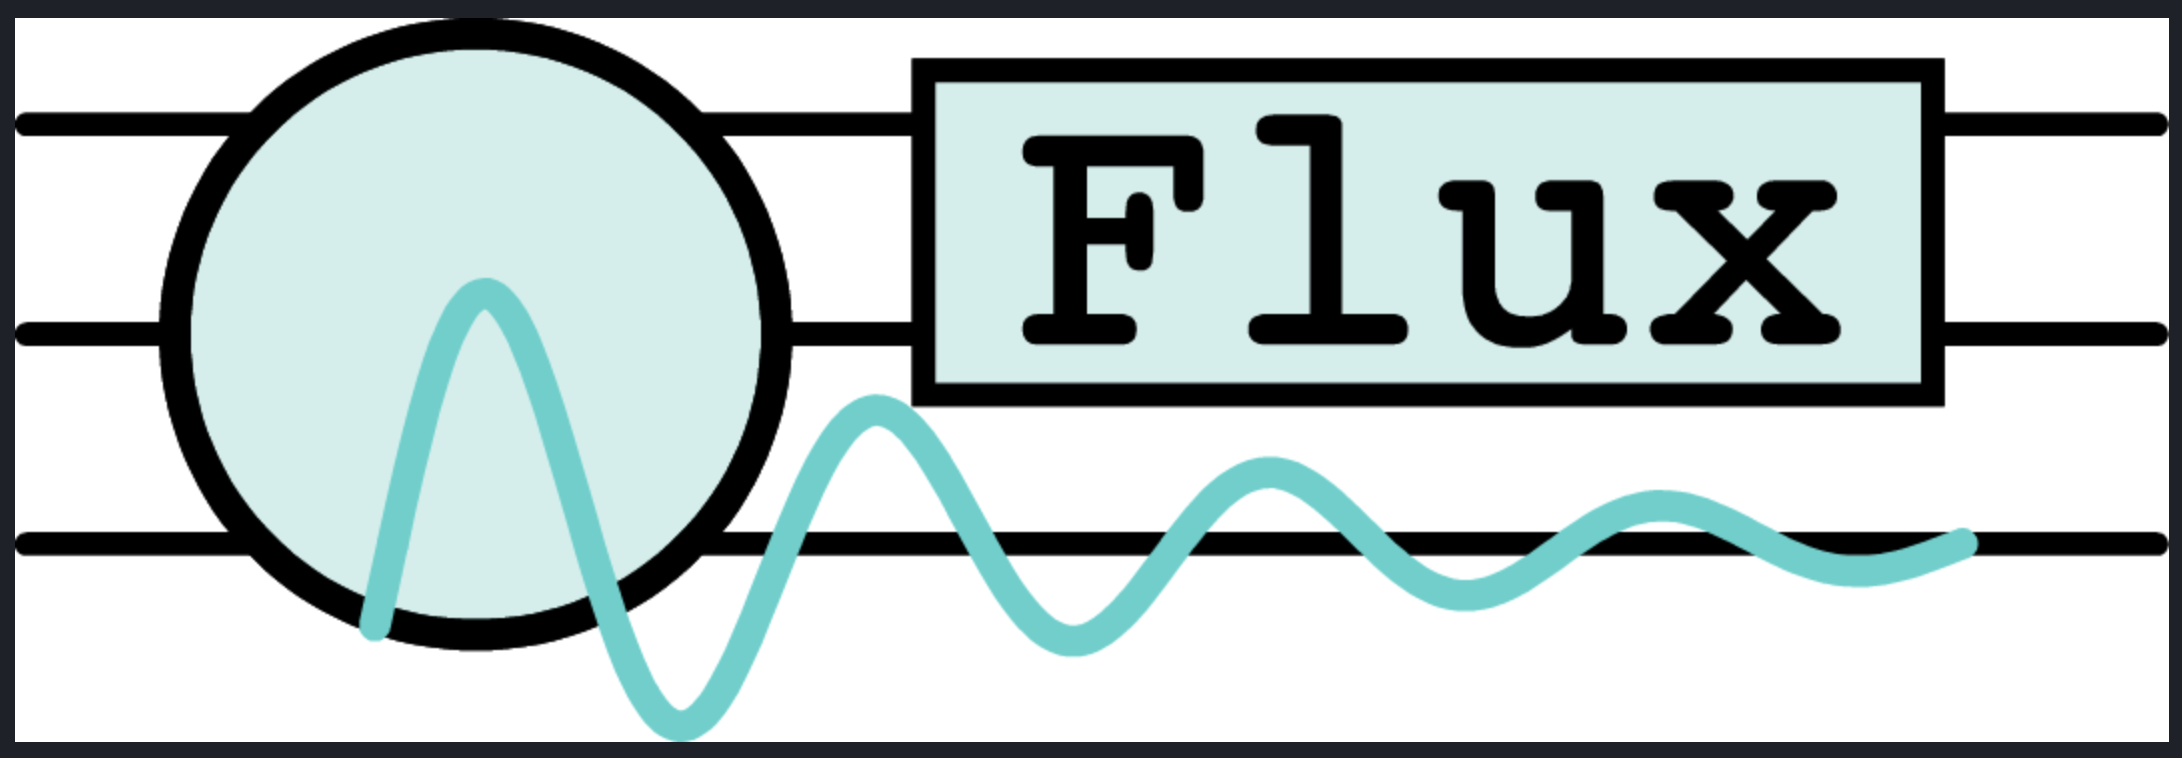
</div>


# **QFlux Tutorial**

<h2> This notebook implements codes referenced in the Supporting Information for: </h2>

<h2> 
<b> QFlux: Quantum Circuit Implementations for Molecular Dynamics </b>
</h2>

<h2> <b>Part VII: Quantum Error Correction and Mitigation</b> </h2>

<h3> 
    <b>Authors:</b> <br><br>
Brandon C. Allen, Chuzhi Xu, Brian Gitahi, Francesco Calcagno, Yue Yu, Alexander V. Soudackov, Ivan Rivalta, and Victor S. Batista
</h3>

**Note:** Each section builds on the previous ones. **Execute the cells sequentially**, as later sections might rely on functions and data defined earlier.

# Table of Contents

* Section 6. Error mitigation with PEC: VQE for the ground state of the Hydrogen molecule with PEC applied to CNOT gates

  - <a href="#ScriptSpt6pt2">Script S.6.2: Two-qubit Hamiltonian for H2 in the minimal STO-3G basis</a>
  - <a href="#ScriptSpt6pt3">Script S.6.3: Two-qubit Hardware-Efficient Ansatz</a>
  - <a href="#ScriptSpt6pt4">Script S.6.4: VQE Energy estimators for H2</a>
  - <a href="#ScriptSpt6pt5">Script S.6.5: Two-qubit VQE driver for H2</a>
  - <a href="#ScriptSpt6pt6">Script S.6.6: VQE calculation workflow for H2</a>


## Two-qubit VQE for the H2 ground state with Probabilistic Error Cancellation (PEC) applied to the CNOT (CX) gate.

### Problem setup

We use the standard parity-mapped, two-qubit-reduced Hamiltonian
for $\mathrm{H}_2$ at bond length $R = 0.7414$ Angstroms,
in the minimal STO-3G basis:

$$
H = c_{II} I\otimes I
  + c_{IZ} I\otimes Z
  + c_{ZI} Z\otimes I
  + c_{ZZ} Z\otimes Z 
  + c_{XX} X\otimes X,
$$

with coefficients (in Hartree)

\begin{align*}
    c_{II} &= -1.052373245772859   \\
    c_{IZ} &=  0.39793742484318045 \\
    c_{ZI} &= -0.39793742484318045 \\
    c_{ZZ} &= -0.01128010425623538 \\
    c_{XX} &=  0.18093119978423156
\end{align*}

The exact (full-CI) ground-state energy of this 2-qubit operator is
$E_0 = -1.857275$ Ha, which already includes the nuclear repulsion term.

### Ansatz

A minimal hardware-efficient ansatz with four single-qubit rotations
and a single entangling CX gate:

\begin{equation*}
    |\psi(\vec{\theta})\rangle = \left[R_y(\theta_3) \otimes R_y(\theta_2)\right]\;.\;CX(0\to 1)\;.\;\left[R_y(\theta_1) \otimes R_y(\theta_0)\right] |00\rangle
\end{equation*}

This ansatz with only 4 parameters can reach the ground state of the $\mathrm{H}_2$ Hamiltonian.

### Noise model

We assume the CX gate is corrupted by a symmetric two-qubit
depolarizing channel of rate $p_2$. The single-qubit Ry gates are taken to
be noiseless. This is a deliberate simplification chosen so that the
PEC mitigation focuses on the dominant noise channel (the two-qubit
gate); the construction extends to noisy Ry gates by adding the
single-qubit PEC decomposition derived in the previous subsection.

### PEC strategy

We use the noise-inversion variant: after every noisy CX we apply a
2-qubit Pauli correction $P$ sampled with probability $|\alpha_P|/\gamma$, and
multiply the measurement outcome by $\mathrm{sgn}(\alpha_P) \gamma$. The Pauli
coefficients $\alpha_P$ are the closed-form decomposition of the inverse
of the 2-qubit depolarizing channel:

\begin{align*}
    \alpha_{II}               &= \dfrac{15 - p}{15 - 16p} \\
    \alpha_{P\neq I\otimes I} &= -  \dfrac{p}{15 - 16p}
\end{align*}

and the one-norm is

\begin{equation*}
    \gamma_2 = \dfrac{15 + 14p}{15 - 16p}
\end{equation*}

### Output

Running the file produces three energy-vs-iteration curves:
ideal (statevector), noisy (no mitigation), and PEC-corrected,
all targeting the same Hamiltonian and same ansatz.

Requirements: qiskit, qiskit-aer, scipy, numpy, matplotlib.

In [1]:
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    print("We are in Google Colab: installing required packages...")
    !pip install -q numpy scipy pylatexenc qiskit qiskit-aer matplotlib
else:
    print("We are not in Google Colab: all the packages are asumed to be installed in the current environment")

from importlib.metadata import version

for pkg in ["numpy", "scipy", "pylatexenc", "qiskit", "qiskit-aer", "matplotlib"]:
    print(f"{pkg}: {version(pkg)}")

We are not in Google Colab: all the packages are asumed to be installed in the current environment
numpy: 2.5.2
scipy: 1.18.0
pylatexenc: 2.11
qiskit: 2.5.2
qiskit-aer: 0.17.2
matplotlib: 3.11.1


In [2]:
from __future__ import annotations

import itertools
import math
from dataclasses import dataclass

import numpy as np
from scipy.optimize import minimize

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error


### Hamiltonian

In [3]:
H2_HAMILTONIAN = SparsePauliOp.from_list([
    ("II", -1.052373245772859),
    ("IZ",  0.39793742484318045),
    ("ZI", -0.39793742484318045),
    ("ZZ", -0.01128010425623538),
    ("XX",  0.18093119978423156),
])

# Exact diagonalization for reference. The Pauli labels in Qiskit are
# read RIGHT-TO-LEFT (the rightmost letter acts on q0), so XX means
# X_0 X_1 etc.

EXACT_GROUND_ENERGY = float(np.linalg.eigvalsh(H2_HAMILTONIAN.to_matrix())[0])

print(f"Exact ground state energy: {EXACT_GROUND_ENERGY:.6f} Hartrees")

Exact ground state energy: -1.857275 Hartrees


### PEC decomposition of the inverse 2-qubit depolarizing channel

In [4]:
@dataclass(frozen=True)
class PECDecomp:
    paulis: tuple
    alphas: np.ndarray
    gamma: float
    probs: np.ndarray
    signs: np.ndarray

def pec_decomposition_depolarizing(p: float, n_qubits: int) -> PECDecomp:
    """
    Closed-form quasi-probability decomposition of (D_p^{(n)})^{-1},
    where D_p^{(n)} is the n-qubit depolarizing channel with depolarizing rate p.
    """
    dim = 4**n_qubits
    if not 0.0 <= p < (dim - 1) / dim:
        raise ValueError("p outside the invertibility range")
    f = 1.0 - dim*p/(dim - 1)
    alpha_I = (dim + f - 1.0)/(dim*f)
    alpha_P = (f - 1.0)/(dim*f)
    labels = tuple(''.join(t) for t in itertools.product('IXYZ', repeat=n_qubits))
    alphas = np.array([alpha_I if lbl == 'I'*n_qubits else alpha_P for lbl in labels])
    gamma = float(np.sum(np.abs(alphas)))
    probs = np.abs(alphas)/gamma
    signs = np.sign(alphas).astype(int)
    return PECDecomp(labels, alphas, gamma, probs, signs)

### Ansatz construction

In [5]:
def build_ansatz(theta: np.ndarray, pec_pauli: str | None = None) -> QuantumCircuit:
    """
    Two-qubit hardware-efficient ansatz: Ry-Ry-CX-Ry-Ry.

    If `pec_pauli` is given (e.g. 'IX', 'ZY'), the corresponding Pauli
    correction is appended *immediately after* the CX, implementing one
    sample of the PEC decomposition (lines 10--14 of Algorithm 1 in the
    main text). When `pec_pauli` is None the bare noisy circuit is
    returned (i.e. no PEC).
    """
    qc = QuantumCircuit(2)
    qc.ry(theta[0], 0)
    qc.ry(theta[1], 1)
    qc.cx(0, 1)
    if pec_pauli is not None:
        for ch, q in zip(pec_pauli, (0, 1)):  # bit 0 -> q0, bit 1 -> q1
            if ch == 'X': qc.x(q)
            elif ch == 'Y': qc.y(q)
            elif ch == 'Z': qc.z(q)
    qc.ry(theta[2], 0)
    qc.ry(theta[3], 1)
    return qc

### Measuring $\langle H\rangle$ in three flavours

In [6]:
def _change_basis_for_pauli(qc: QuantumCircuit, label: str) -> None:
    """Append basis-rotation gates so that measuring in Z reads `label`.

    label is in Qiskit's right-to-left order: label[-1] is q0.
    """
    for q_index, ch in enumerate(reversed(label)):
        if ch == 'X':
            qc.h(q_index)
        elif ch == 'Y':
            qc.sdg(q_index); qc.h(q_index)
        # I and Z need no rotation


def _pauli_expectation_value_from_counts(label: str, counts: dict) -> float:
    """<P> from Z-basis measurement counts, given Pauli label."""
    total = sum(counts.values())
    if total == 0:
        return 0.0
    val = 0.0
    for bitstring, c in counts.items():
        # Qiskit returns bitstrings right-to-left; bit 0 is rightmost
        parity = 0
        for q_index, ch in enumerate(reversed(label)):
            if ch in ('X', 'Y', 'Z'):
                parity ^= int(bitstring[-1 - q_index])
        val += ((-1) ** parity) * c
    return val / total


def energy_ideal(theta: np.ndarray) -> float:
    """Noise-free <H> via statevector simulation."""
    qc = build_ansatz(theta)
    state = Statevector.from_instruction(qc)
    return float(np.real(state.expectation_value(H2_HAMILTONIAN)))


def energy_noisy(theta: np.ndarray,
                 p2: float,
                 shots: int = 4096,
                 seed: int | None = None) -> float:
    """<H> under 2-qubit depolarizing noise on CX, no mitigation."""
    nm = NoiseModel()
    if p2 > 0:
        nm.add_all_qubit_quantum_error(depolarizing_error(p2, 2), ['cx'])
    sim = AerSimulator(noise_model=nm, seed_simulator=seed)

    energy = 0.0
    for pauli, coeff in zip(H2_HAMILTONIAN.paulis.to_labels(),
                            H2_HAMILTONIAN.coeffs.real):
        if pauli == 'II':
            energy += float(coeff)
            continue
        qc = build_ansatz(theta)
        _change_basis_for_pauli(qc, pauli)
        qc.measure_all()
        tqc = transpile(qc, sim, optimization_level=0)
        counts = sim.run(tqc, shots=shots).result().get_counts()
        energy += float(coeff) * _pauli_expectation_value_from_counts(
            pauli, counts)
    return energy


def energy_pec(theta: np.ndarray,
               p2: float,
               num_samples: int = 800,
               shots_per_sample: int = 16,
               seed: int | None = None,
               return_std: bool = False):
    """
    PEC-mitigated <H> under 2-qubit depolarizing noise on CX.

    For each Pauli term P_k in H with coefficient c_k:
      1. draw a Pauli correction with probability |alpha|/Q;
      2. build the ansatz with the correction inserted after CX;
      3. measure P_k on the noisy device;
      4. accumulate sign * Q * <P_k>_{noisy with correction}.
    The term estimate is Q * mean(x_i); the energy is sum_k c_k * that.
 
    Variance estimate
    -----------------
    For each term we also accumulate sum(x_i) and sum(x_i^2), giving the
    unbiased per-sample variance
 
        sigma2_k = (1/(N_s - 1)) * sum_i (x_i - mean_x)^2
 
    which is exactly the sigma^2 entering  N_s ~ Q^2 sigma^2 / eps^2.
    The standard error of that term's contribution to <H> is
 
        SE_k = |c_k| * Q * sqrt(sigma2_k / N_s),
 
    and the standard error of the total energy is the root-sum-square
    SE_tot = sqrt(sum_k SE_k^2), since the terms are sampled with
    independent random draws.
 
    Parameters
    ----------
    return_std : bool
        If False (default) return only the energy as a float, so the
        function is a drop-in objective for the optimizer. If True,
        return (energy, std_dict) where std_dict reports the total
        standard error, the per-term sigma^2 and SE, and the overhead Q.
 
    Performance: all `num_samples` circuits for a given Pauli term are
    submitted to `sim.run` in one batch, which avoids the per-circuit
    dispatch overhead. Each circuit is also run with
    `shots_per_sample > 1` shots: averaging over a small block of shots
    reduces variance at constant total work.
    """
    
    decomp = pec_decomposition_depolarizing(p2, n_qubits=2)
    rng = np.random.default_rng(seed)

    nm = NoiseModel()
    if p2 > 0:
        nm.add_all_qubit_quantum_error(depolarizing_error(p2, 2), ['cx'])
    sim = AerSimulator(noise_model=nm, seed_simulator=seed)

    energy = 0.0
    sigma2_per_term = {}     # pauli label -> estimated per-sample variance
    se_per_term = {}         # pauli label -> std error of c_k * <P_k>
    var_total = 0.0          # running sum of SE_k^2 for the total energy

    for pauli, coeff in zip(H2_HAMILTONIAN.paulis.to_labels(),
                            H2_HAMILTONIAN.coeffs.real):
        if pauli == 'II':
            energy += float(coeff)
            continue

        # Pre-sample all correction indices for this Pauli term.
        idxs = rng.choice(len(decomp.paulis), size=num_samples,
                          p=decomp.probs)

        circuits = []
        signs = np.empty(num_samples, dtype=int)
        for s in range(num_samples):
            correction = decomp.paulis[idxs[s]]
            signs[s] = int(decomp.signs[idxs[s]])
            qc = build_ansatz(theta, pec_pauli=correction)
            _change_basis_for_pauli(qc, pauli)
            qc.measure_all()
            circuits.append(qc)

        # Single batched submission. The ansatz uses only {ry,cx,x,y,z,h,
        # sdg,measure}, all of which AerSimulator runs natively, so we skip
        # transpile() entirely -- transpiling thousands of tiny circuits is
        # the dominant cost otherwise.
        
        #tcs = transpile(circuits, sim, optimization_level=0)
        #result = sim.run(tcs, shots=shots_per_sample).result()
        result = sim.run(circuits, shots=shots_per_sample).result()

        # Collect the per-sample signed estimates x_i in an array so we can
        # take both their mean and their (unbiased) sample variance.
        x = np.empty(num_samples, dtype=float)
        for s in range(num_samples):
            counts = result.get_counts(s)
            p_val = _pauli_expectation_value_from_counts(pauli, counts)
            x[s] = signs[s] * p_val
 
        x_mean = float(x.mean())
        # ddof=1 -> unbiased estimator of the per-sample variance sigma^2.
        sigma2 = float(x.var(ddof=1)) if num_samples > 1 else 0.0
        p_mean = decomp.gamma * x_mean
        energy += float(coeff) * p_mean
 
        # Standard error of this term's contribution c_k * Q * mean(x).
        se_k = abs(float(coeff)) * decomp.gamma * math.sqrt(sigma2 / num_samples)
        sigma2_per_term[pauli] = sigma2
        se_per_term[pauli] = se_k
        var_total += se_k ** 2
 
    if return_std:
        std_info = {
            'std_error': math.sqrt(var_total),   # SE of the total energy
            'sigma2_per_term': sigma2_per_term,   # sigma^2 entering N_s formula
            'se_per_term': se_per_term,           # |c_k| Q sqrt(sigma2/N_s)
            'gamma': decomp.gamma,
            'num_samples': num_samples,
        }
        return energy, std_info
    return energy


### VQE driver

In [7]:
def parameter_shift_gradient(objective, theta, shift=np.pi/2):
    """
    Exact analytic gradient of <H> via the parameter-shift rule.
 
    For every gate of the form exp(-i theta P / 2) (which Ry is), the
    partial derivative is
 
        dE/dtheta_j = 1/2 [ E(theta + (pi/2) e_j) - E(theta - (pi/2) e_j) ].
 
    Note on cost: this exact gradient needs 2*n circuit evaluations per
    step (n = number of parameters).
    """
    grad = np.zeros_like(theta)
    for j in range(len(theta)):
        tp = theta.copy(); tp[j] += shift
        tm = theta.copy(); tm[j] -= shift
        grad[j] = 0.5 * (objective(tp) - objective(tm))

    return grad

In [8]:
def run_vqe(objective, theta0=None, maxiter=80, tol=1e-5, disp=False):
    """
    Run COBYLA minimization, returning (history, result)
    """
    if theta0 is None:
        theta0 = np.array([0.1, -0.1, 0.0, 0.0])  # near Hartree-Fock state

    history = []
    def callback(theta):
        history.append(float(objective(theta)))

    # COBYLA does not call the callback after every iteration cleanly,
    # so wrap the objective to record evaluations directly.
    eval_log = []
    def logged(theta):
        v = float(objective(theta))
        eval_log.append(v)
        return v

    res = minimize(logged, theta0, method='COBYLA',
                   options={'maxiter': maxiter, 'rhobeg': 0.2, 'disp': disp},
                   tol=tol)
    return eval_log, res

### Main demonstration

In [9]:
import time

print(f"Exact ground-state energy of H2 (full diagonalization): {EXACT_GROUND_ENERGY:.6f} Ha")

# 2-qubit depolarizing rate
p2 = 0.02

decomp = pec_decomposition_depolarizing(p2, 2)
print(f"PEC overhead for one CX at p2={p2}: "
      f"one-norm = {decomp.gamma:.4f}, overhead = {decomp.gamma**2:.4f}")

maxiter = 70

# ---- Ideal VQE ----
time_start = time.time()
print("\n[ideal] Running statevector VQE...")
hist_ideal, res_ideal = run_vqe(energy_ideal, maxiter=maxiter)
time_end = time.time()
print(f"  done in {time_end - time_start:.1f} seconds")
print(f"  converged energy: {res_ideal.fun:.6f} Ha "
        f"(error {res_ideal.fun - EXACT_GROUND_ENERGY:+.2e} Ha = {(res_ideal.fun - EXACT_GROUND_ENERGY)*627.5095:+.6f} kcal/mol)")

# ---- Noisy VQE ----
shots = 16_384
time_start = time.time()
print(f"\n[noisy] Running VQE with depolarizing CX noise (no PEC, {shots} shots)...")
hist_noisy, res_noisy = run_vqe(lambda t: energy_noisy(t, p2=p2, shots=shots, seed=0), maxiter=maxiter)
time_end = time.time()
print(f"  done in {time_end - time_start:.1f} seconds")
print(f"  converged energy: {res_noisy.fun:.6f} Ha "
        f"(error {res_noisy.fun - EXACT_GROUND_ENERGY:+.3e} Ha = {(res_noisy.fun - EXACT_GROUND_ENERGY)*627.5095:+.6f} kcal/mol)")

# ---- PEC VQE ----
num_samples = 16_384
shots_per_sample = 1
time_start = time.time()

print(f"\n[PEC]   Running VQE with PEC-corrected CX... ({num_samples} samples, {shots_per_sample} shots/sample)")
hist_pec, res_pec = run_vqe(
        lambda t: energy_pec(t, p2=p2, num_samples=num_samples, shots_per_sample=shots_per_sample, seed=0),
        maxiter=maxiter)
time_end = time.time()
print(f"  done in {time_end - time_start:.1f} seconds")

# Re-evaluate the converged parameters once more,
# asking for the standard-error breakdown
e_pec, std = energy_pec(res_pec.x, p2=p2, num_samples=num_samples,
                        shots_per_sample=shots_per_sample, return_std=True)

print(f"  converged energy: {e_pec:.6f} +/- {std['std_error']:.6f} Ha "
      f"(error {res_pec.fun - EXACT_GROUND_ENERGY:+.2e} Ha = {(res_pec.fun - EXACT_GROUND_ENERGY)*627.5095:+.6f} kcal/mol)"
      f" SE from N_s={std['num_samples']}, gamma={std['gamma']:.4f})")
print("  per-term standard error (|c_k| gamma sqrt(sigma2_k / N_s)):")
for term, se_k in std['se_per_term'].items():
    print(f"    {term}:  sigma^2 = {std['sigma2_per_term'][term]:.3f},"
          f"  Standard Error = {se_k:.6f} Ha = {se_k*627.5095:.2f} kcal/mol")



Exact ground-state energy of H2 (full diagonalization): -1.857275 Ha
PEC overhead for one CX at p2=0.02: one-norm = 1.0409, overhead = 1.0834

[ideal] Running statevector VQE...
  done in 0.2 seconds
  converged energy: -1.857275 Ha (error +2.64e-08 Ha = +0.000017 kcal/mol)

[noisy] Running VQE with depolarizing CX noise (no PEC, 16384 shots)...
  done in 7.0 seconds
  converged energy: -1.838856 Ha (error +1.842e-02 Ha = +11.557838 kcal/mol)

[PEC]   Running VQE with PEC-corrected CX... (16384 samples, 1 shots/sample)
  done in 789.0 seconds
  converged energy: -1.852975 +/- 0.002192 Ha (error +2.30e-03 Ha = +1.445436 kcal/mol) SE from N_s=16384, gamma=1.0409)
  per-term standard error (|c_k| gamma sqrt(sigma2_k / N_s)):
    IZ:  sigma^2 = 0.139,  Standard Error = 0.001206 Ha = 0.76 kcal/mol
    ZI:  sigma^2 = 0.122,  Standard Error = 0.001131 Ha = 0.71 kcal/mol
    ZZ:  sigma^2 = 0.081,  Standard Error = 0.000026 Ha = 0.02 kcal/mol
    XX:  sigma^2 = 0.956,  Standard Error = 0.001439

### VQE Convergence Plot

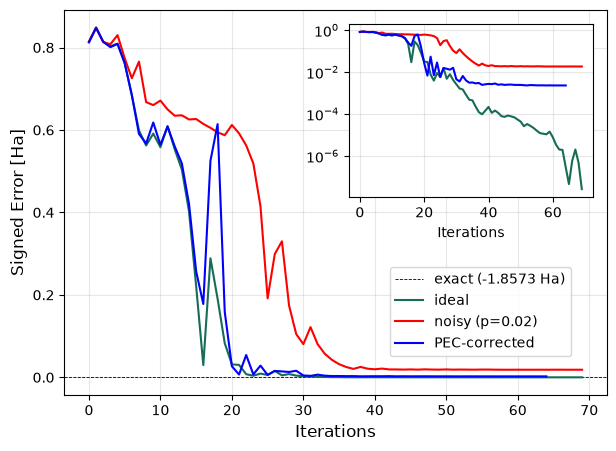

In [13]:
# ---- Optional plot ----
try:
    import matplotlib.pyplot as plt
    from mpl_toolkits.axes_grid1.inset_locator import inset_axes

    fig, ax = plt.subplots(figsize=(7, 5))
    # COBYLA can stop before maxiter, so each run may have a different
    # number of function evaluations. Plot each history on its own x-axis.
    x_ideal = np.arange(len(hist_ideal))
    x_noisy = np.arange(len(hist_noisy))
    x_pec = np.arange(len(hist_pec))
    ax.axhline(0, color='k', ls='--',
               lw=0.6, label=f'exact ({EXACT_GROUND_ENERGY:.4f} Ha)')
    ax.plot(x_ideal, np.array(hist_ideal) - EXACT_GROUND_ENERGY, label='ideal', color="#156C57")
    ax.plot(x_noisy, np.array(hist_noisy) - EXACT_GROUND_ENERGY, label=f'noisy (p={p2})', color='red')
    ax.plot(x_pec, np.array(hist_pec) - EXACT_GROUND_ENERGY, label=f'PEC-corrected', color='blue')
    ax.set_xlabel('Iterations', fontsize=12)
    ax.set_ylabel('Signed Error [Ha]', fontsize=12)
    ax.legend(loc=(0.6, 0.1), fontsize=10)
    #ax.set_title(r'VQE convergence for H$_2$ at $R=0.7414$ Å', fontsize=14)
    ax.grid(alpha=0.3)

    axins = inset_axes(ax, width='45%', height='45%', loc='upper right', borderpad=1)
    axins.plot(x_ideal, np.abs(np.array(hist_ideal) - EXACT_GROUND_ENERGY), color="#156C57")
    axins.plot(x_noisy, np.abs(np.array(hist_noisy) - EXACT_GROUND_ENERGY), color='red')
    axins.plot(x_pec, np.abs(np.array(hist_pec) - EXACT_GROUND_ENERGY), color='blue')
    axins.set_yscale('log')
    axins.set_xlabel('Iterations', fontsize=10)
    #axins.set_ylabel('Signed Error [Ha]', fontsize=8)
    axins.tick_params(axis='both', labelsize=10)
    #axins.grid(True, which='both', linestyle=':', linewidth=0.5)
    axins.grid(alpha=0.3)

    fig.savefig('vqe_h2_convergence_linear_with_log_inset.png', dpi=300)
    plt.show()

except ImportError:
    pass